# Figure 2: expression-space UMAPs

UMAPs of the matched scRNA-seq reference and one Xenium section before cleaning, after SPLIT purification, after ResolVI correction, after ovrlpy correction at the 0.7 VSI threshold, and after Syndri cleaning. CellAdmix uses the corrected-count layer from the matched CellAdmix AnnData result. Cells with fewer than 10 counts or 5 detected genes are excluded before embedding. Set `PLOT_PANELS` to the subset of panels to compute and display. Set `QC_CELL_SELECTION` to `'intersection'` to use cells passing QC in every selected spatial method, or `'per_method'` to use each method's own QC-passing cells. Spatial panels use the same genes in either mode. Each populated panel is embedded independently so that changes in expression-space structure remain visible.

In [4]:
from pathlib import Path
import warnings

import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_hex
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import seaborn as sns

sc.settings.verbosity = 2
sns.set_theme(style="white", context="paper")

# The selected B1_3 section is shared by the final and competitor AnnData files.
SLICE_ID = 'GSM9509174_breast_breast_B1_B1_3'
REFERENCE_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad')
SPATIAL_PATH = Path(f'/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/final/{SLICE_ID}_rctd_annotated.h5ad')
RESOLVI_PATH = Path(f'/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/competitors/resolvi/{SLICE_ID}_rctd_annotated.h5ad')
OVRLPY_PATH = Path(f'/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/competitors/ovrlpy_pixel_correction/{SLICE_ID}_rctd_annotated.h5ad')
CELLADMIX_PATH = Path(f'/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/competitors/celladmix_k1p5ct/{SLICE_ID}_rctd_annotated.h5ad')
OUTPUT_DIR = Path('/home/jwinchel/Syndri/figures/outputs')
QC_CELL_SELECTION = 'intersection'  # 'intersection' or 'per_method'
# Select and order panels here. For example: ['Raw spatial', 'ResolVI-corrected', 'Syndri-cleaned'].
PLOT_PANELS = [
    'scRNA-seq reference',
    'Raw spatial',
    'SPLIT-purified',
    'ResolVI-corrected',
    'ovrlpy 0.7-corrected',
    'CellAdmix',
    'Syndri-cleaned',
]
PANEL_TAGS = {
    'scRNA-seq reference': 'reference',
    'Raw spatial': 'raw',
    'SPLIT-purified': 'split',
    'ResolVI-corrected': 'resolvi',
    'ovrlpy 0.7-corrected': 'ovrlpy07',
    'CellAdmix': 'celladmix',
    'Syndri-cleaned': 'syndri',
}
if not PLOT_PANELS or len(PLOT_PANELS) != len(set(PLOT_PANELS)):
    raise ValueError('PLOT_PANELS must contain unique panel names and cannot be empty')
unknown_panels = set(PLOT_PANELS) - set(PANEL_TAGS)
if unknown_panels:
    raise ValueError(f'Unknown PLOT_PANELS: {sorted(unknown_panels)}')
panel_tag = '_'.join(PANEL_TAGS[panel] for panel in PLOT_PANELS)
OUTPUT_STEM = OUTPUT_DIR / (
    f'Figure2_UMAPs_qc10counts5genes_syndriMinP03_{QC_CELL_SELECTION}QC_{SLICE_ID}'
    f'{SPATIAL_PATH.stem}_{panel_tag}'
)

REFERENCE_LAYER = 'SoupX'
REFERENCE_LABEL = 'cell_type'
SPATIAL_LABEL = 'harmony_cell_type'
PROBABILITY_LAYER = 'syndri_admix_probs_X'
SPLIT_LAYER = 'split_purified_counts_X'
RESOLVI_LAYER = 'resolvi_corrected_counts'
OVRLPY_LAYER = 'ovrlpy_corrected_counts_vsi_lt_0_7'
CELLADMIX_LAYER = 'celladmix_corrected_counts'
TARGET_REMOVED_FRACTION = 0.50
MIN_SYNDRI_REMOVAL_PROBABILITY = 0.5
MIN_COUNTS = 10
MIN_GENES = 5
MAX_SPATIAL_CELLS = None  # Use every cell from this one spatial slice.
N_PCS = 50
N_NEIGHBORS = 15
MIN_DIST = 0.4
RANDOM_STATE = 42
POINT_SIZE = 2.0
if QC_CELL_SELECTION not in {'intersection', 'per_method'}:
    raise ValueError("QC_CELL_SELECTION must be 'intersection' or 'per_method'")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# for output_path in (OUTPUT_STEM.with_suffix('.pdf'), OUTPUT_STEM.with_suffix('.png')):
    # if output_path.exists():
    #     raise FileExistsError(f'Refusing to overwrite existing UMAP figure: {output_path}')

## Load and validate inputs

The reference uses SoupX-corrected counts. Spatial labels, Syndri probabilities, and SPLIT counts come from the final annotated Xenium object. ResolVI and ovrlpy 0.7 counts come from their matched competitor AnnData files. The ovrlpy layer excludes transcripts at pixels with VSI below 0.7.

In [5]:
input_paths = [REFERENCE_PATH, SPATIAL_PATH]
if 'ResolVI-corrected' in PLOT_PANELS:
    input_paths.append(RESOLVI_PATH)
if 'ovrlpy 0.7-corrected' in PLOT_PANELS:
    input_paths.append(OVRLPY_PATH)
if 'CellAdmix' in PLOT_PANELS:
    input_paths.append(CELLADMIX_PATH)
for path in input_paths:
    if not path.exists():
        raise FileNotFoundError(path)

reference = ad.read_h5ad(REFERENCE_PATH)
spatial = ad.read_h5ad(SPATIAL_PATH)
resolvi = ad.read_h5ad(RESOLVI_PATH) if 'ResolVI-corrected' in PLOT_PANELS else None
ovrlpy = ad.read_h5ad(OVRLPY_PATH) if 'ovrlpy 0.7-corrected' in PLOT_PANELS else None
celladmix = ad.read_h5ad(CELLADMIX_PATH) if 'CellAdmix' in PLOT_PANELS else None
competitors = {'ResolVI': resolvi, 'ovrlpy': ovrlpy, 'CellAdmix': celladmix}
for method, competitor in competitors.items():
    if competitor is not None and (
        not spatial.obs_names.equals(competitor.obs_names)
        or not spatial.var_names.equals(competitor.var_names)
    ):
        raise ValueError(f'{method} cells and genes do not match the final spatial AnnData')

required = {'spatial label': (SPATIAL_LABEL, spatial.obs)}
if 'scRNA-seq reference' in PLOT_PANELS:
    required['reference layer'] = (REFERENCE_LAYER, reference.layers)
    required['reference label'] = (REFERENCE_LABEL, reference.obs)
if 'Syndri-cleaned' in PLOT_PANELS:
    required['Syndri probabilities'] = (PROBABILITY_LAYER, spatial.layers)
if 'SPLIT-purified' in PLOT_PANELS:
    required['SPLIT counts'] = (SPLIT_LAYER, spatial.layers)
if resolvi is not None:
    required['ResolVI counts'] = (RESOLVI_LAYER, resolvi.layers)
if ovrlpy is not None:
    required['ovrlpy 0.7 counts'] = (OVRLPY_LAYER, ovrlpy.layers)
if celladmix is not None:
    required['CellAdmix counts'] = (CELLADMIX_LAYER, celladmix.layers)
missing = [description for description, (key, container) in required.items() if key not in container]
if missing:
    raise KeyError(f'Missing required inputs: {missing}')

def feature_names(adata):
    if 'feature_name' in adata.var:
        return pd.Index(adata.var['feature_name'].astype(str))
    return pd.Index(adata.var_names.astype(str))

reference.var_names = feature_names(reference)
spatial.var_names = feature_names(spatial)
for competitor in competitors.values():
    if competitor is not None:
        competitor.var_names = feature_names(competitor)
for adata in (reference, spatial, *[c for c in competitors.values() if c is not None]):
    adata.var_names_make_unique()
for method, competitor in competitors.items():
    if competitor is not None and not spatial.var_names.equals(competitor.var_names):
        raise ValueError(f'{method} feature names do not match the final spatial AnnData')
common_genes = spatial.var_names[spatial.var_names.isin(reference.var_names)]
if len(common_genes) < 3:
    raise ValueError(f'Only {len(common_genes)} shared genes were found')
reference = reference[:, common_genes].copy()
spatial = spatial[:, common_genes].copy()
for method, competitor in competitors.items():
    if competitor is not None:
        competitors[method] = competitor[:, common_genes].copy()

valid = spatial.obs[SPATIAL_LABEL].notna() & spatial.obs[SPATIAL_LABEL].astype(str).ne('nan')
spatial = spatial[valid].copy()
for method, competitor in competitors.items():
    if competitor is not None:
        competitors[method] = competitor[valid].copy()
if MAX_SPATIAL_CELLS is not None and spatial.n_obs > MAX_SPATIAL_CELLS:
    rng = np.random.default_rng(RANDOM_STATE)
    keep = np.sort(rng.choice(spatial.n_obs, MAX_SPATIAL_CELLS, replace=False))
    spatial = spatial[keep].copy()
    for method, competitor in competitors.items():
        if competitor is not None:
            competitors[method] = competitor[keep].copy()
resolvi, ovrlpy = competitors['ResolVI'], competitors['ovrlpy']
celladmix = competitors['CellAdmix']

print(f'Reference: {reference.n_obs:,} cells x {reference.n_vars:,} shared genes')
print(f'Spatial:   {spatial.n_obs:,} cells x {spatial.n_vars:,} shared genes')
print(f'Spatial sample: {SPATIAL_PATH.name}')


Reference: 10,658 cells x 270 shared genes
Spatial:   108,069 cells x 270 shared genes
Spatial sample: GSM9509174_breast_breast_B1_B1_3_rctd_annotated.h5ad


## Construct the Syndri-cleaned matrix

Within each annotated cell type, the probability cutoff targets the requested fraction of transcript count mass, but never falls below `MIN_SYNDRI_REMOVAL_PROBABILITY`. Transcripts with smaller admixture probabilities are always retained. If too few transcripts meet the probability floor, the achieved removal fraction will be below the target.


In [6]:
def as_csr(matrix):
    return matrix.tocsr().astype(np.float32) if sp.issparse(matrix) else sp.csr_matrix(np.asarray(matrix, dtype=np.float32))

def clean_by_cell_type(counts, probabilities, labels, target_fraction, min_probability):
    counts = as_csr(counts)
    probabilities = as_csr(probabilities)
    if counts.shape != probabilities.shape:
        raise ValueError('Counts and Syndri probabilities must have identical shapes')
    if not 0 <= target_fraction <= 1:
        raise ValueError('TARGET_REMOVED_FRACTION must be between 0 and 1')
    if not np.isfinite(min_probability) or not 0 <= min_probability <= 1:
        raise ValueError('MIN_SYNDRI_REMOVAL_PROBABILITY must be between 0 and 1')

    cleaned = counts.copy()
    labels = np.asarray(labels).astype(str)
    records = []
    for label in pd.unique(labels):
        rows = np.flatnonzero(labels == label)
        block = counts[rows].tocoo()
        total = float(block.data.sum())
        if block.nnz == 0 or total == 0:
            records.append((label, np.inf, 0.0))
            continue
        p = np.asarray(probabilities[rows][block.row, block.col]).ravel()
        eligible = p >= min_probability
        if target_fraction == 0 or not np.any(eligible):
            records.append((label, np.inf, 0.0))
            continue
        eligible_probabilities = p[eligible]
        eligible_counts = block.data[eligible]
        order = np.argsort(eligible_probabilities)[::-1]
        cumulative = np.cumsum(eligible_counts[order], dtype=np.float64)
        stop = min(np.searchsorted(cumulative, target_fraction * total, side='left'), len(order) - 1)
        threshold = float(eligible_probabilities[order[stop]])
        remove = eligible & (p >= threshold)
        records.append((label, threshold, float(block.data[remove].sum() / total)))

        block_clean = cleaned[rows].tolil()
        for local_row, col in zip(block.row[remove], block.col[remove]):
            block_clean[local_row, col] = 0
        cleaned[rows] = block_clean.tocsr()

    cleaned.eliminate_zeros()
    thresholds = pd.DataFrame(records, columns=['cell_type', 'admix_prob_threshold', 'achieved_removed_fraction'])
    return cleaned, thresholds

raw_counts = as_csr(spatial.X)
spatial_matrices = {}
for panel in PLOT_PANELS:
    if panel == 'Raw spatial':
        spatial_matrices[panel] = raw_counts
    elif panel == 'SPLIT-purified':
        spatial_matrices[panel] = as_csr(spatial.layers[SPLIT_LAYER])
    elif panel == 'ResolVI-corrected':
        spatial_matrices[panel] = as_csr(resolvi.layers[RESOLVI_LAYER])
    elif panel == 'ovrlpy 0.7-corrected':
        spatial_matrices[panel] = as_csr(ovrlpy.layers[OVRLPY_LAYER])
    elif panel == 'CellAdmix':
        spatial_matrices[panel] = as_csr(celladmix.layers[CELLADMIX_LAYER])
    elif panel == 'Syndri-cleaned':
        syndri_counts, syndri_thresholds = clean_by_cell_type(
            raw_counts, spatial.layers[PROBABILITY_LAYER], spatial.obs[SPATIAL_LABEL],
            TARGET_REMOVED_FRACTION, MIN_SYNDRI_REMOVAL_PROBABILITY,
        )
        spatial_matrices[panel] = syndri_counts
        display(syndri_thresholds.sort_values('cell_type').reset_index(drop=True))
for panel, counts in spatial_matrices.items():
    if counts.shape != raw_counts.shape:
        raise ValueError(f'{panel} counts do not match the selected spatial cells and genes')


,cell_type,admix_prob_threshold,achieved_removed_fraction
0,"CD4-positive, alpha-beta memory T cell",0.978149,0.500004
1,capillary endothelial cell,0.935520,0.500000
2,classical monocyte,0.987678,0.500015
3,cytotoxic T cell,0.980156,0.500002
4,fibroblast of breast,0.972107,0.500000
5,fibroblast of lung,0.512626,0.500000
6,macrophage,0.941998,0.500000
7,malignant cell,0.500002,0.432730
8,mast cell,0.990151,0.500082
9,natural T-regulatory cell,0.990236,0.500007


## Compute independent UMAPs

Before normalization, retain cells with at least 10 counts and 5 detected genes in each count matrix. The reference is filtered on its own counts. With `QC_CELL_SELECTION = 'intersection'`, all selected spatial panels use the same cells passing QC in each selected method's counts. With `'per_method'`, each spatial panel uses its own QC-passing cells; the printed counts show the difference. All matrices then use the metric pipeline's per-cell normalization to 10,000, log transform, and 50-PC representation before the neighbor graph and UMAP. Gene-wise scaling is omitted, as in the separation metrics.


In [7]:
def compute_umap(template, matrix, label_key, title):
    current = ad.AnnData(
        X=as_csr(matrix),
        # Retain every observation-level annotation for downstream coloring.
        obs=template.obs.copy(),
        var=template.var.copy(),
    )
    current.obs['cell_type_plot'] = current.obs[label_key].astype(str)
    sc.pp.normalize_total(current, target_sum=10_000)
    sc.pp.log1p(current)
    n_comps = min(N_PCS, current.n_obs - 1, current.n_vars - 1)
    if n_comps < 2:
        raise ValueError(f'{title}: insufficient observations or genes for PCA')
    sc.pp.pca(current, n_comps=n_comps, random_state=RANDOM_STATE)
    sc.pp.neighbors(current, n_neighbors=min(N_NEIGHBORS, current.n_obs - 1), n_pcs=n_comps, random_state=RANDOM_STATE)
    sc.tl.umap(current, min_dist=MIN_DIST, random_state=RANDOM_STATE)
    return current

def qc_pass(matrix):
    matrix = as_csr(matrix)
    total_counts = np.asarray(matrix.sum(axis=1)).ravel()
    detected_genes = np.asarray((matrix > 0).sum(axis=1)).ravel()
    return (total_counts >= MIN_COUNTS) & (detected_genes >= MIN_GENES)

umap_adatas = {}
if 'scRNA-seq reference' in PLOT_PANELS:
    reference_counts = as_csr(reference.layers[REFERENCE_LAYER])
    reference_keep = qc_pass(reference_counts)
    if reference_keep.sum() < 3:
        raise ValueError('Too few reference cells pass count and gene QC')
    print(f'Reference QC: {reference_keep.sum():,}/{reference.n_obs:,} cells retained')
    reference_qc = reference[reference_keep].copy()
    umap_adatas['scRNA-seq reference'] = compute_umap(
        reference_qc, reference_counts[reference_keep], REFERENCE_LABEL, 'reference',
    )

spatial_qc_masks = {}
spatial_intersection = np.ones(spatial.n_obs, dtype=bool)
for title, matrix in spatial_matrices.items():
    method_keep = qc_pass(matrix)
    spatial_qc_masks[title] = method_keep
    print(f'{title} QC: {method_keep.sum():,}/{spatial.n_obs:,} cells pass')
    spatial_intersection &= method_keep
if spatial_matrices:
    print(f'Selected-method intersection QC: {spatial_intersection.sum():,}/{spatial.n_obs:,} cells pass')

for title, matrix in spatial_matrices.items():
    keep = spatial_intersection if QC_CELL_SELECTION == 'intersection' else spatial_qc_masks[title]
    if keep.sum() < 3:
        raise ValueError(f'{title}: too few cells pass {QC_CELL_SELECTION} QC')
    print(f'{title} UMAP ({QC_CELL_SELECTION} QC): {keep.sum():,} cells')
    umap_adatas[title] = compute_umap(spatial[keep], matrix[keep], SPATIAL_LABEL, title)
print('Finished:', ', '.join(umap_adatas))


Reference QC: 9,145/10,658 cells retained
normalizing counts per cell


    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:02)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:23)
computing UMAP
    finished (0:00:28)
Raw spatial QC: 108,062/108,069 cells pass
SPLIT-purified QC: 106,076/108,069 cells pass
ResolVI-corrected QC: 108,011/108,069 cells pass
ovrlpy 0.7-corrected QC: 97,264/108,069 cells pass
CellAdmix QC: 107,979/108,069 cells pass
Syndri-cleaned QC: 99,334/108,069 cells pass
Selected-method intersection QC: 90,428/108,069 cells pass
Raw spatial UMAP (intersection QC): 90,428 cells
normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:01)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:07)
computing UMAP
    finished (0:01:35)
SPLIT-purified UMAP (intersection QC): 90,428 cells
normalizing counts per cell
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:01)
computing neighbors
    using 'X_pca' w

## Plot and export Figure 2 panel

A single deterministic palette is shared across all panels; labels absent from an individual panel remain represented consistently.

In [13]:
import seaborn as sns

palette = (
    sns.color_palette("Blues", 6)[1:] +       # lymphoid
    sns.color_palette("Reds", 5)[1:] +     # myeloid / innate
    sns.color_palette("Purples", 2)[1:]  +         # malignant
    sns.color_palette("Greens", 6)[1:]      # stromal / vascular
)
cell_type_order = [
    # Lymphoid
    "CD4-positive, alpha-beta memory T cell",
    "cytotoxic T cell",
    "natural T-regulatory cell",
    "natural killer cell",
    "plasma cell",

    # Myeloid / innate
    "classical monocyte",
    "macrophage",
    "mast cell",
    "plasmacytoid dendritic cell",
    # Malignant
    "malignant cell",

    # Stromal / vascular
    "capillary endothelial cell",
    "fibroblast of breast",
    "fibroblast of lung",
    "pericyte",
    "smooth muscle cell",


]

palette_dict = dict(zip(cell_type_order, palette))


In [9]:
palette_dict

{'CD4-positive, alpha-beta memory T cell': (0.7309496347558632,
  0.8394771241830065,
  0.9213225682429834),
 'cytotoxic T cell': (0.5356862745098039,
  0.746082276047674,
  0.8642522106881968),
 'natural T-regulatory cell': (0.32628988850442137,
  0.6186236063052672,
  0.802798923490965),
 'natural killer cell': (0.16696655132641292,
  0.48069204152249134,
  0.7291503267973857),
 'plasma cell': (0.044059976931949255, 0.3338869665513264, 0.6244521337946944),
 'classical monocyte': (0.9882352941176471,
  0.6261437908496732,
  0.5084967320261438),
 'macrophage': (0.9835755478662053, 0.4127950788158401, 0.28835063437139563),
 'mast cell': (0.8901960784313725, 0.18562091503267975, 0.15294117647058825),
 'plasmacytoid dendritic cell': (0.6943944636678201,
  0.07003460207612457,
  0.09231833910034601),
 'capillary endothelial cell': (0.7371472510572856,
  0.895517108804306,
  0.7108342945021145),
 'fibroblast of breast': (0.5573241061130334,
  0.8164244521337947,
  0.546958861976163),
 'fibr

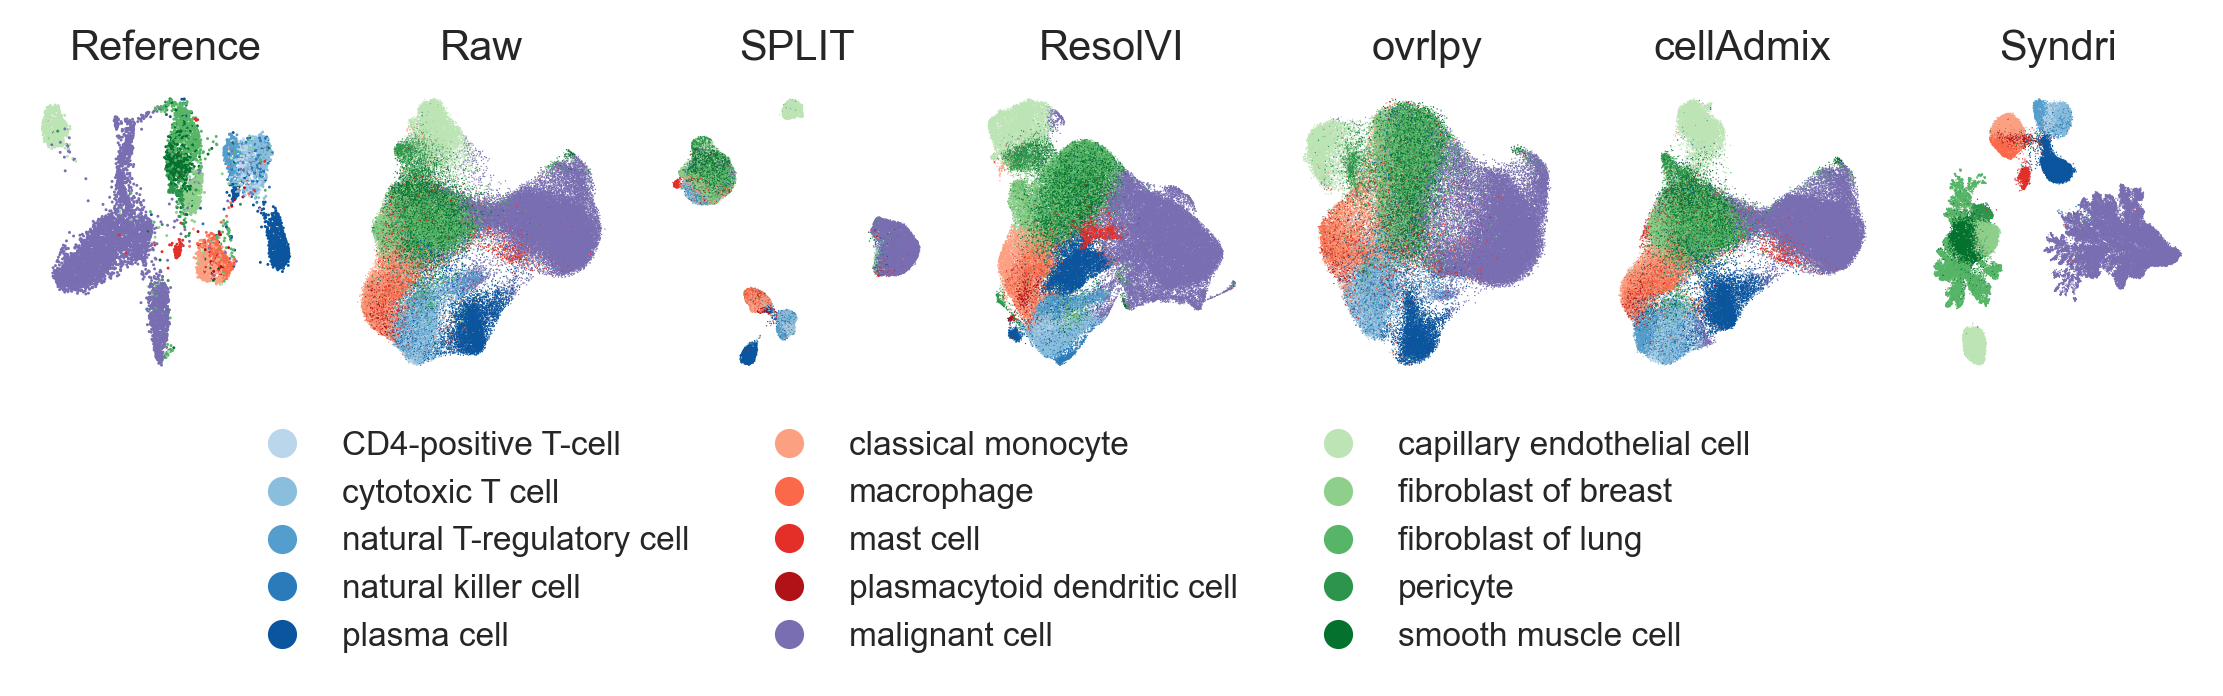

Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_qc10counts5genes_syndriMinP03_intersectionQC_GSM9509174_breast_breast_B1_B1_3GSM9509174_breast_breast_B1_B1_3_rctd_annotated_reference_raw_split_resolvi_ovrlpy07_celladmix_syndri.pdf
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_qc10counts5genes_syndriMinP03_intersectionQC_GSM9509174_breast_breast_B1_B1_3GSM9509174_breast_breast_B1_B1_3_rctd_annotated_reference_raw_split_resolvi_ovrlpy07_celladmix_syndri.png


In [35]:
import seaborn as sns
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

font_path = '/home/jwinchel/fonts/ARIAL.TTF'  
fm.fontManager.addfont(font_path)
mpl.rcParams['svg.fonttype'] = 'none'
# Set Arial globally
plt.rcParams['font.family'] = 'Arial'
# sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,

})
plot_order = PLOT_PANELS
missing_panels = [title for title in plot_order if title not in umap_adatas]
if missing_panels:
    raise KeyError(f'Missing UMAP panels: {missing_panels}')
plot_items = [(title, umap_adatas.get(title)) for title in plot_order]

categories = sorted({
    value
    for _, current in plot_items if current is not None
    for value in current.obs['cell_type_plot'].dropna().astype(str).unique()
})
colors = sns.color_palette('tab20', n_colors=len(categories))
# palette = dict(zip(categories, map(to_hex, colors)))
for _, current in plot_items:
    if current is not None:
        current.obs['cell_type_plot'] = pd.Categorical(current.obs['cell_type_plot'], categories=categories)

fig, axes = plt.subplots(1, len(plot_items), figsize=(7.5, 1.45),
                         dpi=300, squeeze=False)
axes = axes.ravel()
point_sizes = {'scRNA-seq reference': 0.5, 'Raw spatial': 0.10,
               'SPLIT-purified': 0.10, 'ResolVI-corrected': 0.10,
               'ovrlpy 0.7-corrected': 0.10, 'CellAdmix': 0.10, 'Syndri-cleaned': 0.10}
panel_titles = {'scRNA-seq reference': 'Reference', 'Raw spatial': 'Raw',
                'SPLIT-purified': 'SPLIT', 'ResolVI-corrected': 'ResolVI',
                'ovrlpy 0.7-corrected': 'ovrlpy', 'CellAdmix': 'cellAdmix',
                'Syndri-cleaned': 'Syndri'}
for i, (ax, (title, current)) in enumerate(zip(axes, plot_items)):
    if current is None:
        raise ValueError(f'{title}: UMAP data were not computed')
    # sc.pl.umap(
    #     current, color='cell_type_plot', palette=palette, title=title, ax=ax, show=False,
    #     frameon=False, legend_loc=None, size=POINT_SIZE, alpha=0.75, rasterized=True,
    # )
    sns.scatterplot(data=current.obs, x=current.obsm['X_umap'][:,0],y=current.obsm['X_umap'][:,1],hue='cell_type_plot',hue_order=cell_type_order,palette=palette_dict,s=point_sizes[title],legend=False,ax=ax,edgecolor='none')
    ax.set_title(panel_titles[title], fontsize=10)
    ax.axis('off')

# Small UMAP coordinate arrows on the first panel only.
axis_ax = axes[0]
origin = (0.00, 0.00)
# axis_ax.annotate('', xy=(0.25, origin[1]), xytext=origin, xycoords='axes fraction', arrowprops=dict(arrowstyle='-|>', color='black', lw=2, mutation_scale=7))
# axis_ax.annotate('', xy=(origin[0], 0.25), xytext=origin, xycoords='axes fraction', arrowprops=dict(arrowstyle='-|>', color='black', lw=2, mutation_scale=7))
# axis_ax.text(0.125, -0.035, 'UMAP1', transform=axis_ax.transAxes, ha='center', va='top', fontsize=12)
# axis_ax.text(-0.035, 0.125, 'UMAP2', transform=axis_ax.transAxes, ha='right', va='center', rotation=90, fontsize=12)

legend_labels  = ['CD4-positive T-cell' if 'CD4' in x else x for x in cell_type_order]
handles = [Line2D([0], [0], marker='o', linestyle='', markerfacecolor=palette_dict[c], markeredgecolor='none', markersize=7, label=c) for c in cell_type_order]
fig.legend(handles=handles, labels=legend_labels, title='', loc='outside lower center', frameon=False, ncol=3, fontsize=8,bbox_to_anchor=(0.45,-0.6))
fig.tight_layout(rect=(0, 0, 1, 1))
fig.savefig(OUTPUT_STEM.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(OUTPUT_STEM.with_suffix('.png'), dpi=600, bbox_inches='tight')
plt.show()
print(f'Saved {OUTPUT_STEM.with_suffix(".pdf")}')
print(f'Saved {OUTPUT_STEM.with_suffix(".png")}')

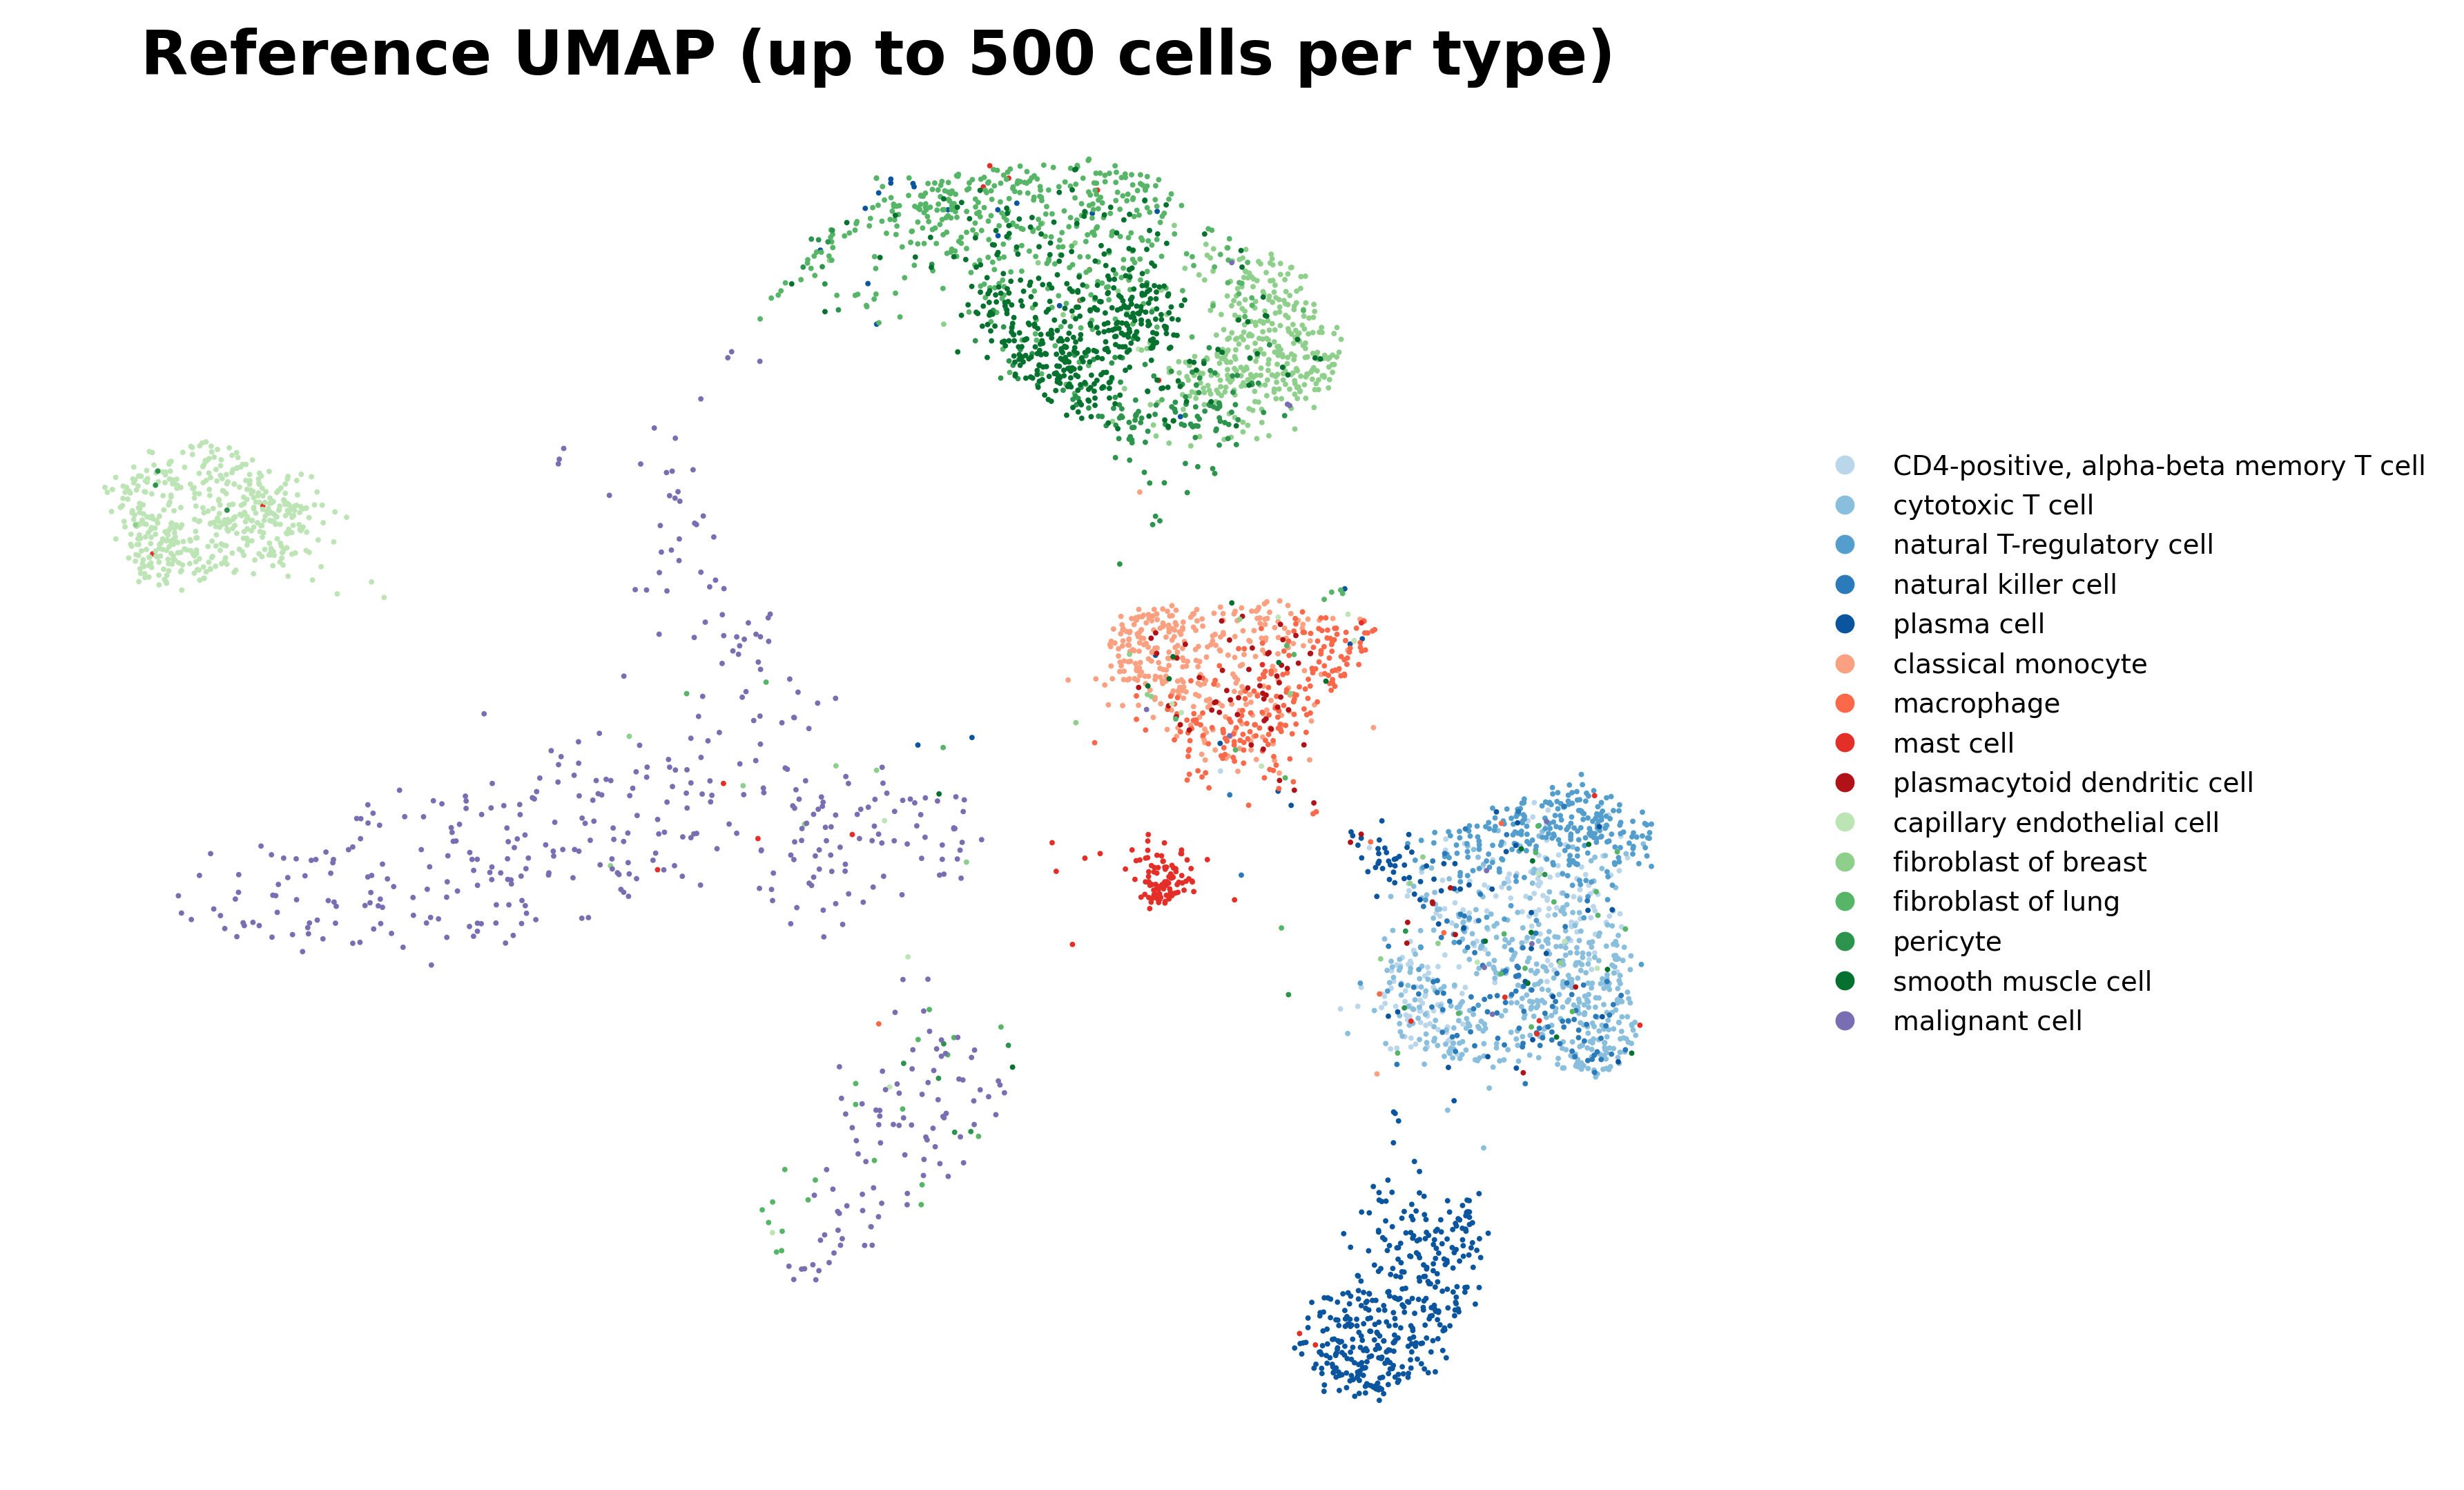

Reference QC retained: 9,205/10,658
Displayed cells: 4,835
Saved: /home/jwinchel/Syndri/figures/outputs/Figure2_Reference_UMAP_subsampled_N500_per_type.pdf
Saved: /home/jwinchel/Syndri/figures/outputs/Figure2_Reference_UMAP_subsampled_N500_per_type.png


In [ ]:
# Standalone subsampled Reference UMAP.
# Edit N_PER_TYPE to control the maximum number of displayed cells per cell type.
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import scanpy as sc
import scipy.sparse as sp
import seaborn as sns

REFERENCE_UMAP_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad')
REFERENCE_UMAP_LAYER = 'SoupX'
REFERENCE_UMAP_LABEL = 'cell_type'
N_PER_TYPE = 500
SUBSAMPLE_RANDOM_STATE = 42
REFERENCE_UMAP_MIN_COUNTS = 10
REFERENCE_UMAP_MIN_GENES = 5
REFERENCE_UMAP_N_PCS = 50
REFERENCE_UMAP_N_NEIGHBORS = 15
REFERENCE_UMAP_MIN_DIST = 0.4
REFERENCE_UMAP_OUTPUT_DIR = Path('/home/jwinchel/Syndri/figures/outputs')
REFERENCE_UMAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# This is the same ordered cell-type palette used by the multi-panel figure above.
CELL_TYPE_ORDER = [
    'CD4-positive, alpha-beta memory T cell',
    'cytotoxic T cell',
    'natural T-regulatory cell',
    'natural killer cell',
    'plasma cell',
    'classical monocyte',
    'macrophage',
    'mast cell',
    'plasmacytoid dendritic cell',
    'capillary endothelial cell',
    'fibroblast of breast',
    'fibroblast of lung',
    'pericyte',
    'smooth muscle cell',
    'malignant cell',
]
CELL_TYPE_COLORS = (
    sns.color_palette('Blues', 6)[1:]
    + sns.color_palette('Reds', 5)[1:]
    + sns.color_palette('Greens', 6)[1:]
    + sns.color_palette('Purples', 2)[1:]
)
CELL_TYPE_PALETTE = dict(zip(CELL_TYPE_ORDER, CELL_TYPE_COLORS))

if N_PER_TYPE < 1:
    raise ValueError('N_PER_TYPE must be a positive integer')
if not REFERENCE_UMAP_PATH.is_file():
    raise FileNotFoundError(REFERENCE_UMAP_PATH)
reference_subsample_source = ad.read_h5ad(REFERENCE_UMAP_PATH)
if REFERENCE_UMAP_LABEL not in reference_subsample_source.obs:
    raise KeyError(f'Missing reference label column: {REFERENCE_UMAP_LABEL}')
if REFERENCE_UMAP_LAYER not in reference_subsample_source.layers:
    raise KeyError(f'Missing reference expression layer: {REFERENCE_UMAP_LAYER}')

# Recreate the full Reference UMAP using the same QC and embedding settings, then
# subsample only the displayed points so sampling does not change the embedding geometry.
reference_subsample_counts = reference_subsample_source.layers[REFERENCE_UMAP_LAYER]
if sp.issparse(reference_subsample_counts):
    reference_subsample_counts = reference_subsample_counts.tocsr()
else:
    reference_subsample_counts = sp.csr_matrix(np.asarray(reference_subsample_counts))
reference_subsample_total = np.asarray(reference_subsample_counts.sum(axis=1)).ravel()
reference_subsample_detected = np.asarray((reference_subsample_counts > 0).sum(axis=1)).ravel()
reference_subsample_keep = (
    (reference_subsample_total >= REFERENCE_UMAP_MIN_COUNTS)
    & (reference_subsample_detected >= REFERENCE_UMAP_MIN_GENES)
)
if reference_subsample_keep.sum() < 3:
    raise ValueError('Too few reference cells pass count and gene QC')
reference_subsample_adata = ad.AnnData(
    X=reference_subsample_counts[reference_subsample_keep].copy(),
    obs=reference_subsample_source.obs.loc[reference_subsample_keep].copy(),
    var=reference_subsample_source.var.copy(),
)
reference_subsample_adata.obs['cell_type_plot'] = (
    reference_subsample_adata.obs[REFERENCE_UMAP_LABEL].astype(str)
)
unknown_reference_types = set(reference_subsample_adata.obs.cell_type_plot.unique()) - set(CELL_TYPE_ORDER)
if unknown_reference_types:
    raise ValueError(f'Cell types missing from the figure palette: {sorted(unknown_reference_types)}')
sc.pp.normalize_total(reference_subsample_adata, target_sum=10_000)
sc.pp.log1p(reference_subsample_adata)
reference_subsample_n_comps = min(
    REFERENCE_UMAP_N_PCS,
    reference_subsample_adata.n_obs - 1,
    reference_subsample_adata.n_vars - 1,
)
if reference_subsample_n_comps < 2:
    raise ValueError('Insufficient observations or genes for PCA')
sc.pp.pca(reference_subsample_adata, n_comps=reference_subsample_n_comps,
          random_state=SUBSAMPLE_RANDOM_STATE)
sc.pp.neighbors(
    reference_subsample_adata,
    n_neighbors=min(REFERENCE_UMAP_N_NEIGHBORS, reference_subsample_adata.n_obs - 1),
    n_pcs=reference_subsample_n_comps,
    random_state=SUBSAMPLE_RANDOM_STATE,
)
sc.tl.umap(reference_subsample_adata, min_dist=REFERENCE_UMAP_MIN_DIST,
           random_state=SUBSAMPLE_RANDOM_STATE)

reference_subsample_labels = reference_subsample_adata.obs.cell_type_plot.to_numpy()
reference_subsample_coordinates = reference_subsample_adata.obsm['X_umap']
reference_subsample_rng = np.random.default_rng(SUBSAMPLE_RANDOM_STATE)
reference_subsample_indices = {}
for cell_type in CELL_TYPE_ORDER:
    candidates = np.flatnonzero(reference_subsample_labels == cell_type)
    n_selected = min(N_PER_TYPE, len(candidates))
    if n_selected:
        reference_subsample_indices[cell_type] = np.sort(
            reference_subsample_rng.choice(candidates, size=n_selected, replace=False)
        )

fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=300)
for cell_type in CELL_TYPE_ORDER:
    indices = reference_subsample_indices.get(cell_type, np.array([], dtype=int))
    if len(indices):
        ax.scatter(
            reference_subsample_coordinates[indices, 0],
            reference_subsample_coordinates[indices, 1],
            s=2, color=CELL_TYPE_PALETTE[cell_type], edgecolor='none', rasterized=True,
        )
ax.set_title(f'Reference UMAP (up to {N_PER_TYPE:,} cells per type)', fontsize=16, fontweight='bold')
ax.axis('off')
legend_handles = [
    Line2D([0], [0], marker='o', linestyle='', markerfacecolor=CELL_TYPE_PALETTE[cell_type],
           markeredgecolor='none', markersize=5, label=cell_type)
    for cell_type in CELL_TYPE_ORDER if cell_type in reference_subsample_indices
]
fig.legend(handles=legend_handles, loc='center left', bbox_to_anchor=(.77, .5),
           frameon=False, fontsize=7)
fig.tight_layout(rect=(0, 0, .76, 1))
reference_subsample_stem = REFERENCE_UMAP_OUTPUT_DIR / f'Figure2_Reference_UMAP_subsampled_N{N_PER_TYPE}_per_type'
fig.savefig(reference_subsample_stem.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(reference_subsample_stem.with_suffix('.png'), dpi=400, bbox_inches='tight')
plt.show()
print(f'Reference QC retained: {reference_subsample_keep.sum():,}/{reference_subsample_source.n_obs:,}')
print(f'Displayed cells: {sum(len(indices) for indices in reference_subsample_indices.values()):,}')
print('Saved:', reference_subsample_stem.with_suffix('.pdf'))
print('Saved:', reference_subsample_stem.with_suffix('.png'))


In [11]:
# Export each previously computed panel as a scatter-only high-resolution PNG,
# and write the matching cell-type legend separately as a vector SVG.
from pathlib import Path
from matplotlib.lines import Line2D

INDIVIDUAL_UMAP_DIR = OUTPUT_DIR / 'Figure2_UMAPs_individual'
INDIVIDUAL_UMAP_DIR.mkdir(parents=True, exist_ok=True)
INDIVIDUAL_UMAP_DPI = 600
INDIVIDUAL_UMAP_SIZE = (1.15, 1.15)

missing_exports = [panel for panel in PLOT_PANELS if panel not in umap_adatas]
if missing_exports:
    raise KeyError(f'UMAP panels have not been computed: {missing_exports}')

for panel in PLOT_PANELS:
    current = umap_adatas[panel]
    coords = np.asarray(current.obsm['X_umap'])
    labels = current.obs['cell_type_plot'].astype(str).to_numpy()
    unknown_types = set(pd.unique(labels)) - set(cell_type_order)
    if unknown_types:
        raise ValueError(f'{panel} has cell types missing from cell_type_order: {sorted(unknown_types)}')

    fig, ax = plt.subplots(figsize=INDIVIDUAL_UMAP_SIZE)
    for cell_type in cell_type_order:
        selected = labels == cell_type
        if not selected.any():
            continue
        ax.scatter(
            coords[selected, 0], coords[selected, 1],
            s=point_sizes.get(panel, POINT_SIZE),
            color=palette_dict[cell_type], edgecolors='none',
        )
    ax.set_aspect('equal', adjustable='datalim')
    ax.margins(0.02)
    ax.axis('off')
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    output_path = INDIVIDUAL_UMAP_DIR / f'{PANEL_TAGS[panel]}_scatter.png'
    fig.tight_layout()
    fig.savefig(
        output_path, dpi=INDIVIDUAL_UMAP_DPI, bbox_inches='tight',
        pad_inches=0, facecolor='white',
    )
    plt.close(fig)
    print(f'Saved {output_path}')

legend_labels = [
    'CD4-positive T-cell' if 'CD4' in cell_type else cell_type
    for cell_type in cell_type_order
]
legend_handles = [
    Line2D(
        [0], [0], marker='o', linestyle='',
        markerfacecolor=palette_dict[cell_type], markeredgecolor='none',
        markersize=6, label=label,
    )
    for cell_type, label in zip(cell_type_order, legend_labels)
]
legend_fig = plt.figure(figsize=(5.0, 1))
legend_fig.legend(
    handles=legend_handles, labels=legend_labels, loc='center', ncol=3,
    frameon=False, fontsize=8, columnspacing=1.4, handletextpad=0.5,
)
legend_path = INDIVIDUAL_UMAP_DIR / 'cell_type_legend.svg'
with plt.rc_context({'svg.fonttype': 'none'}):
    legend_fig.savefig(legend_path, format='svg', bbox_inches='tight', pad_inches=0.03)
plt.close(legend_fig)
print(f'Saved {legend_path}')


Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_individual/reference_scatter.png
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_individual/raw_scatter.png
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_individual/split_scatter.png
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_individual/resolvi_scatter.png
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_individual/ovrlpy07_scatter.png
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_individual/celladmix_scatter.png
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_individual/syndri_scatter.png
Saved /home/jwinchel/Syndri/figures/outputs/Figure2_UMAPs_individual/cell_type_legend.svg
